<a href="https://colab.research.google.com/github/aniket-s9/Car_Price_Predictor/blob/main/Price_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import files
print(files.upload())

Saving car_price_dataset.csv to car_price_dataset.csv
{'car_price_dataset.csv': b'Car_ID,Brand,Model_Year,Engine_Size,Fuel_Type,Transmission,Mileage,Doors,Owner_Count,Horsepower,Price\r\n1,Ford,2023,1.2,Hybrid,Manual,180635,4,3,82,34309.25\r\n2,Hyundai,2018,3.2,Electric,Manual,35628,2,4,259,55153.6\r\n3,BMW,2008,2.2,Diesel,Manual,74672,3,2,333,41894.4\r\n4,Hyundai,2017,2.2,Petrol,Automatic,51246,4,4,381,54046.7\r\n5,Hyundai,2012,2.4,Electric,Manual,147233,3,4,290,38010.35\r\n6,Honda,2023,3.5,Petrol,Automatic,94110,2,4,173,54182.5\r\n7,BMW,2016,2.3,Petrol,Manual,7810,2,3,267,52140.5\r\n8,BMW,2022,3.9,Petrol,Automatic,195932,4,1,369,61707.4\r\n9,BMW,2010,2.6,Electric,Manual,76688,3,1,238,44992.6\r\n10,Hyundai,2022,1.3,Electric,Manual,70548,4,4,218,40924.6\r\n11,Ford,2023,4.1,Petrol,Automatic,198435,2,3,318,56053.25\r\n12,BMW,2009,2.1,Diesel,Automatic,16162,3,2,325,49052.9\r\n13,Tesla,2013,2.7,Petrol,Automatic,92858,4,4,111,34220.1\r\n14,Hyundai,2007,3.7,Diesel,Manual,78535,4,2,271,46273.

In [7]:
import pandas as pd
df=pd.read_csv("car_price_dataset.csv")
print(df)
df.describe()

      Car_ID    Brand  Model_Year  Engine_Size Fuel_Type Transmission  \
0          1     Ford        2023          1.2    Hybrid       Manual   
1          2  Hyundai        2018          3.2  Electric       Manual   
2          3      BMW        2008          2.2    Diesel       Manual   
3          4  Hyundai        2017          2.2    Petrol    Automatic   
4          5  Hyundai        2012          2.4  Electric       Manual   
...      ...      ...         ...          ...       ...          ...   
1995    1996  Hyundai        2023          4.5    Diesel       Manual   
1996    1997   Toyota        2023          1.4    Petrol       Manual   
1997    1998  Hyundai        2022          4.1    Diesel       Manual   
1998    1999      BMW        2020          4.4    Diesel    Automatic   
1999    2000    Honda        2012          1.7  Electric    Automatic   

      Mileage  Doors  Owner_Count  Horsepower     Price  
0      180635      4            3          82  34309.25  
1      

,Car_ID,Model_Year,Engine_Size,Mileage,Doors,Owner_Count,Horsepower,Price
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000
mean,1000.500000,2013.963000,2.967550,100736.956500,2.988000,2.532500,235.70950,46169.507675
std,577.494589,5.508248,1.146926,56002.915221,0.818041,1.125423,95.59811,9211.685713
min,1.000000,2005.000000,1.000000,5036.000000,2.000000,1.000000,70.00000,18911.550000
25%,500.750000,2009.000000,2.000000,52365.500000,2.000000,2.000000,154.00000,39764.000000
50%,1000.500000,2014.000000,2.900000,100590.500000,3.000000,3.000000,236.00000,46112.350000
75%,1500.250000,2019.000000,4.000000,148024.500000,4.000000,4.000000,319.00000,52471.387500
max,2000.000000,2023.000000,5.000000,199904.000000,4.000000,4.000000,399.00000,72267.800000


In [17]:
import numpy as np

#x=df.loc[:,"Model_Year":"Horsepower"].to_numpy()
x = df.select_dtypes(include=np.number).drop(columns=["Price"]).to_numpy()
y=df["Price"].to_numpy()

x = (x - x.mean(axis=0)) / x.std(axis=0)

losses=[]
Rmse=[]
w=np.zeros(x.shape[1])
b=0.0
lr=0.01
epochs=400

n=len(x)
for i in range(epochs):
  y_predict=np.dot(x,w)+b

  error=y-y_predict

  dw=(-2/n)*np.dot(x.T,error)
  db=(-2/n)*np.sum(error)

  w=w-lr*dw
  b=b-lr*db

  loss=np.mean(error**2)
  rmse=np.sqrt(loss)
  losses.append(loss)
  Rmse.append(rmse)
  if i%100==0:
      print(f"Epoch :{i+1}/{epochs} - loss: {loss:.4f} - Rmse: {rmse:.4f}")

epoch=list(i for i in range(epochs))

Epoch :1/400 - loss: 2216436165.0579 - Rmse: 47079.0417
Epoch :101/400 - loss: 42045555.6474 - Rmse: 6484.2544
Epoch :201/400 - loss: 3597938.9787 - Rmse: 1896.8234
Epoch :301/400 - loss: 2915466.5945 - Rmse: 1707.4737


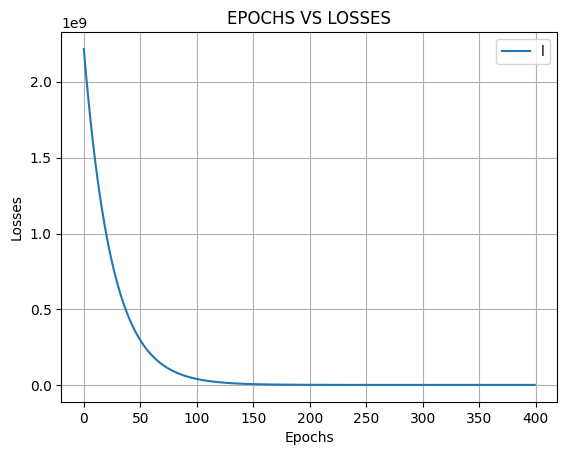

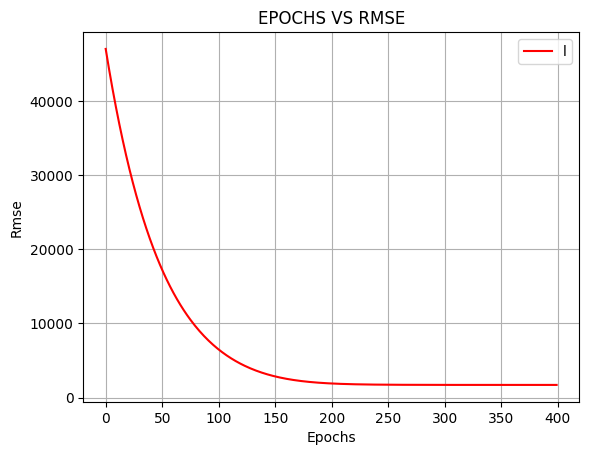

In [22]:
import matplotlib.pyplot as plt
plt.plot(epoch,losses)
plt.legend("losses")
plt.title("EPOCHS VS LOSSES")
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.grid(True)
plt.show()

plt.plot(epoch,Rmse,color="Red")
plt.legend("losses")
plt.title("EPOCHS VS RMSE")
plt.xlabel("Epochs")
plt.ylabel("Rmse")
plt.grid(True)
plt.show()

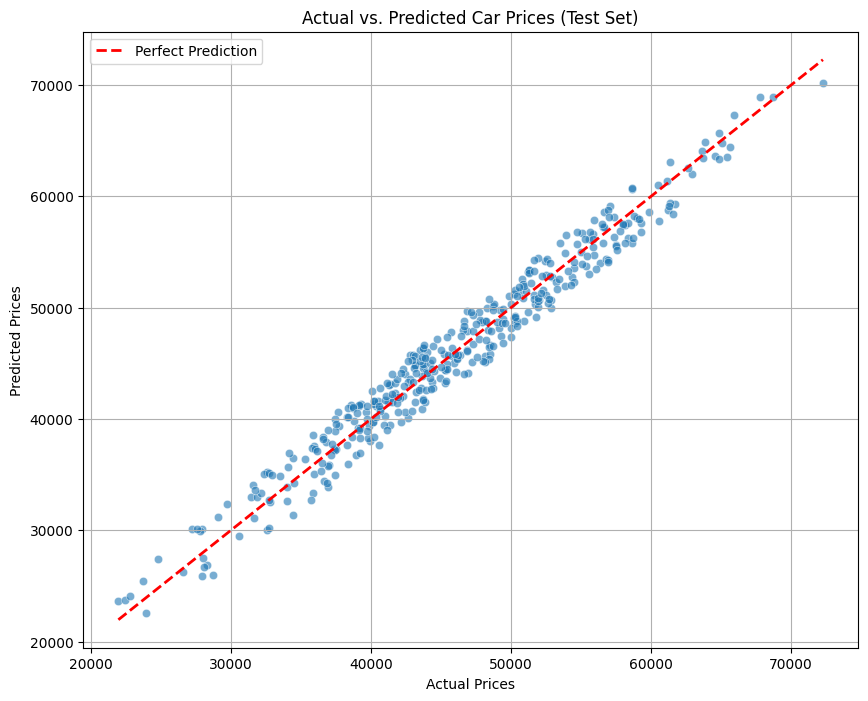

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.scatterplot(x=y_test, y=y_pred_test, alpha=0.6)

# Add a diagonal line for perfect predictions
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')

plt.title('Actual vs. Predicted Car Prices (Test Set)')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.grid(True)
plt.legend()
plt.show()